In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt
from pathlib import Path

In [2]:
dataset_path = Path("../media_pipe_keypoints_dataset")

In [3]:
sample_fileA = next((dataset_path / "A").glob("*.csv"))
sample_dataA = pd.read_csv(sample_fileA)

In [4]:
sample_dataA

,Landmark,X,Y,Z,Visibility
0,0,0.744429,0.581924,-6.026165e-07,0.0
1,1,0.691539,0.547401,-1.216695e-02,0.0
2,2,0.655457,0.477827,-1.855999e-02,0.0
3,3,0.639551,0.424605,-2.710856e-02,0.0
4,4,0.621996,0.386795,-3.342106e-02,0.0
5,5,0.682897,0.422616,-6.398701e-03,0.0
6,6,0.671914,0.384894,-3.587177e-02,0.0
7,7,0.674388,0.433572,-5.346560e-02,0.0
8,8,0.676975,0.481201,-5.967977e-02,0.0
9,9,0.720246,0.427955,-1.108401e-02,0.0


In [5]:
processed_sample = sample_dataA[["Landmark", "X", "Y", "Z"]]

In [6]:
processed_sample.head()


,Landmark,X,Y,Z
0,0,0.744429,0.581924,-6.026165e-07
1,1,0.691539,0.547401,-1.216695e-02
2,2,0.655457,0.477827,-1.855999e-02
3,3,0.639551,0.424605,-2.710856e-02
4,4,0.621996,0.386795,-3.342106e-02


In [7]:
processed_sample.shape

(21, 4)

In [8]:
coordinates = processed_sample[["X", "Y", "Z"]].to_numpy()

In [9]:
coordinates.shape

(21, 3)

In [10]:
flattened_sample = coordinates.flatten()

In [11]:
flattened_sample = coordinates.flatten()

In [12]:
flattened_sample.shape

(63,)

In [13]:
for class_folder in dataset_path.iterdir():
    if class_folder.is_dir():
        print(class_folder.name)

A
B
C
Confirm
D
E
F
G
H
I
J
K
L
M
N
O
P
Q
R
S
Space
Speak
T
U
V
W
X
Y


In [14]:
for class_folder in dataset_path.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name

        for csv_file in class_folder.glob("*.csv"):
            print(class_name, csv_file.name)
            break
            

A A_1.csv
B B_1.csv
C C_1.csv
Confirm Confirm_1.csv
D D_1.csv
E E_1 2.csv
F F_1.csv
G G_1.csv
H H_1.csv
I I_1.csv
J J_1.csv
K K_1.csv
L L_1.csv
M M_1.csv
N M_1742836098913.csv
O O_1.csv
P P_1.csv
Q Q_1.csv
R R_1.csv
S S_1.csv
Space Space_1.csv
Speak Speak_1.csv
T T_1.csv
U U_1.csv
V V_1.csv
W W_1.csv
X X_1.csv
Y Y_1.csv


In [15]:
total_files = 0

for class_folder in dataset_path.iterdir():
    if class_folder.is_dir():
        csv_files = list(class_folder.glob("*.csv"))

        print(class_folder.name, ":", len(csv_files))

        total_files += len(csv_files)

print("Total CSV files:", total_files)

A : 2672
B : 2710
C : 2234
Confirm : 2786
D : 2549
E : 2499
F : 2673
G : 2359
H : 2928
I : 2329
J : 2617
K : 1926
L : 2149
M : 2232
N : 2544
O : 2507
P : 1855
Q : 1175
R : 2289
S : 2258
Space : 1114
Speak : 1742
T : 3909
U : 2608
V : 2698
W : 2368
X : 1477
Y : 1169
Total CSV files: 64376


In [16]:
for class_folder in dataset_path.iterdir():
    if class_folder.is_dir():

        class_name = class_folder.name
        csv_file = next(class_folder.glob("*.csv"))

        sample_data = pd.read_csv(csv_file)

        coordinates = sample_data[["X", "Y", "Z"]].to_numpy()

        flattened_sample = coordinates.flatten()

        print(
            class_name,
            coordinates.shape,
            flattened_sample.shape
        )

A (21, 3) (63,)
B (21, 3) (63,)
C (21, 3) (63,)
Confirm (21, 3) (63,)
D (21, 3) (63,)
E (21, 3) (63,)
F (21, 3) (63,)
G (21, 3) (63,)
H (21, 3) (63,)
I (21, 3) (63,)
J (21, 3) (63,)
K (21, 3) (63,)
L (21, 3) (63,)
M (21, 3) (63,)
N (21, 3) (63,)
O (21, 3) (63,)
P (21, 3) (63,)
Q (21, 3) (63,)
R (21, 3) (63,)
S (21, 3) (63,)
Space (21, 3) (63,)
Speak (21, 3) (63,)
T (21, 3) (63,)
U (21, 3) (63,)
V (21, 3) (63,)
W (21, 3) (63,)
X (21, 3) (63,)
Y (21, 3) (63,)


In [17]:
X = []
y = []
source_files = []

In [18]:
for class_folder in dataset_path.iterdir():

    if class_folder.is_dir():

        class_name = class_folder.name

        for csv_file in class_folder.glob("*.csv"):

            sample_data = pd.read_csv(csv_file)

            coordinates = sample_data[
                ["X", "Y", "Z"]
            ].to_numpy()

            flattened_sample = coordinates.flatten()

            # Store features
            X.append(flattened_sample)

            # Store class label
            y.append(class_name)

            # Store original CSV filename
            source_files.append(str(csv_file))

In [20]:
X = np.array(X)
y = np.array(y)
source_files = np.array(source_files)

print("Feature matrix:", X.shape)
print("Label array:", y.shape)
print("Source files:", source_files.shape)

Feature matrix: (64376, 63)
Label array: (64376,)
Source files: (64376,)


In [21]:
from sklearn.model_selection import train_test_split

original_train = np.load(
    "../dataset/processed/X_train_original.npy"
)

original_test = np.load(
    "../dataset/processed/X_test_original.npy"
)

recreated_indices = np.arange(len(X))

train_indices, test_indices = train_test_split(
    recreated_indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    "Training features match:",
    np.array_equal(X[train_indices], original_train)
)

print(
    "Testing features match:",
    np.array_equal(X[test_indices], original_test)
)

Training features match: True
Testing features match: True


In [22]:
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)

print("First sample features:", X[0])
print("First sample label:", y[0])

Feature matrix shape: (64376, 63)
Label array shape: (64376,)
First sample features: [ 7.44428515e-01  5.81924081e-01 -6.02616524e-07  6.91538751e-01
  5.47401130e-01 -1.21669471e-02  6.55456603e-01  4.77827132e-01
 -1.85599923e-02  6.39550626e-01  4.24605250e-01 -2.71085650e-02
  6.21996164e-01  3.86794746e-01 -3.34210582e-02  6.82897031e-01
  4.22615707e-01 -6.39870111e-03  6.71914101e-01  3.84894103e-01
 -3.58717665e-02  6.74387991e-01  4.33572143e-01 -5.34655973e-02
  6.76975489e-01  4.81201440e-01 -5.96797727e-02  7.20245898e-01
  4.27954972e-01 -1.10840118e-02  7.08251119e-01  3.96784246e-01
 -4.37903740e-02  7.07019567e-01  4.58768159e-01 -5.40385880e-02
  7.05301762e-01  5.11394441e-01 -5.26294038e-02  7.56188273e-01
  4.39616114e-01 -1.95009112e-02  7.43508756e-01  4.14881557e-01
 -5.23149595e-02  7.39749253e-01  4.79534239e-01 -4.99828123e-02
  7.36320734e-01  5.29902935e-01 -3.82331572e-02  7.90747166e-01
  4.57099676e-01 -2.85462905e-02  7.79251754e-01  4.30817455e-01
 -5.0

In [23]:
import re

timestamps = []

for file_path in source_files:

    filename = Path(file_path).stem

    match = re.search(r"_(\d{13})$", filename)

    if match:
        timestamps.append(int(match.group(1)))
    else:
        timestamps.append(None)

timestamps = np.array(timestamps, dtype=object)

print("Total samples:", len(source_files))
print("Timestamped samples:", sum(t is not None for t in timestamps))
print("Missing timestamps:", sum(t is None for t in timestamps))

Total samples: 64376
Timestamped samples: 29282
Missing timestamps: 35094


In [24]:
unique_labels, label_counts = np.unique(y, return_counts=True)

print("Number of unique classes:", len(unique_labels))

for label, count in zip(unique_labels, label_counts):
    print(label, ":", count)

Number of unique classes: 28
A : 2672
B : 2710
C : 2234
Confirm : 2786
D : 2549
E : 2499
F : 2673
G : 2359
H : 2928
I : 2329
J : 2617
K : 1926
L : 2149
M : 2232
N : 2544
O : 2507
P : 1855
Q : 1175
R : 2289
S : 2258
Space : 1114
Speak : 1742
T : 3909
U : 2608
V : 2698
W : 2368
X : 1477
Y : 1169


In [25]:
print("NaN values:", np.isnan(X).sum())

NaN values: 0


In [26]:
print("Infinite values:", np.isinf(X).sum())

Infinite values: 0


In [27]:
print("Minimum value:", np.min(X))
print("Maximum value:", np.max(X))

Minimum value: -0.4362047612667084
Maximum value: 1.0813055038452148


In [28]:
print("X coordinate range:")
print("Minimum:", X[:, 0::3].min())
print("Maximum:", X[:, 0::3].max())

print("\nY coordinate range:")
print("Minimum:", X[:, 1::3].min())
print("Maximum:", X[:, 1::3].max())

print("\nZ coordinate range:")
print("Minimum:", X[:, 2::3].min())
print("Maximum:", X[:, 2::3].max())

X coordinate range:
Minimum: -0.021573975682258606
Maximum: 1.024948000907898

Y coordinate range:
Minimum: -0.07355926185846329
Maximum: 1.0813055038452148

Z coordinate range:
Minimum: -0.4362047612667084
Maximum: 0.1799222230911255


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [30]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (51500, 63)
Testing features: (12876, 63)
Training labels: (51500,)
Testing labels: (12876,)


In [31]:
#Data Scallling

In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
scaler = StandardScaler()

In [34]:
X_train_scaled = scaler.fit_transform(X_train)

In [35]:
X_test_scaled = scaler.transform(X_test)

In [36]:
print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("Original testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

Original training shape: (51500, 63)
Scaled training shape: (51500, 63)
Original testing shape: (12876, 63)
Scaled testing shape: (12876, 63)
Training mean: -8.339487556709698e-18
Training standard deviation: 1.0000000000000002


In [37]:
print("First 10 feature means:")
print(X_train_scaled.mean(axis=0)[:10])

print("\nFirst 10 feature standard deviations:")
print(X_train_scaled.std(axis=0)[:10])

First 10 feature means:
[-2.50651711e-16  2.50538533e-17  4.02698371e-17  1.58979626e-16
  2.14468141e-16 -4.50645454e-17 -2.02332218e-16  1.75579616e-17
 -2.82325404e-17  1.93377137e-16]

First 10 feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [38]:
from pathlib import Path

processed_path = Path("../dataset/processed")
processed_path.mkdir(parents=True, exist_ok=True)

In [39]:
import numpy as np

np.save(processed_path / "X_train_scaled.npy", X_train_scaled)
np.save(processed_path / "X_test_scaled.npy", X_test_scaled)

np.save(processed_path / "y_train.npy", y_train)
np.save(processed_path / "y_test.npy", y_test)

np.save(processed_path / "X_train_original.npy", X_train)
np.save(processed_path / "X_test_original.npy", X_test)

In [40]:
import joblib

joblib.dump(scaler, processed_path / "standard_scaler.pkl")

['..\\dataset\\processed\\standard_scaler.pkl']

In [41]:
for file in processed_path.iterdir():
    print(file.name)

standard_scaler.pkl
X_test_original.npy
X_test_scaled.npy
X_train_original.npy
X_train_scaled.npy
y_test.npy
y_train.npy


In [42]:
# Create metadata for every ASL sample

metadata_df = pd.DataFrame({
    "sample_index": np.arange(len(X)),
    "label": y,
    "source_file": source_files,
    "timestamp": timestamps
})

# Extract filename separately
metadata_df["filename"] = metadata_df["source_file"].apply(
    lambda path: Path(path).name
)

# Check metadata
display(metadata_df.head(10))

print("\nMetadata shape:", metadata_df.shape)
print("Missing timestamps:",
      metadata_df["timestamp"].isna().sum())

,sample_index,label,source_file,timestamp,filename
0,0,A,..\media_pipe_keypoints_dataset\A\A_1.csv,None,A_1.csv
1,1,A,..\media_pipe_keypoints_dataset\A\A_10.csv,None,A_10.csv
2,2,A,..\media_pipe_keypoints_dataset\A\A_100.csv,None,A_100.csv
3,3,A,..\media_pipe_keypoints_dataset\A\A_1000.csv,None,A_1000.csv
4,4,A,..\media_pipe_keypoints_dataset\A\A_1001.csv,None,A_1001.csv
5,5,A,..\media_pipe_keypoints_dataset\A\A_1002.csv,None,A_1002.csv
6,6,A,..\media_pipe_keypoints_dataset\A\A_1003.csv,None,A_1003.csv
7,7,A,..\media_pipe_keypoints_dataset\A\A_1004.csv,None,A_1004.csv
8,8,A,..\media_pipe_keypoints_dataset\A\A_1005.csv,None,A_1005.csv
9,9,A,..\media_pipe_keypoints_dataset\A\A_1006.csv,None,A_1006.csv



Metadata shape: (64376, 5)
Missing timestamps: 35094


In [43]:
timestamp_summary = (
    metadata_df
    .assign(has_timestamp=metadata_df["timestamp"].notna())
    .groupby("label")
    .agg(
        total_samples=("sample_index", "count"),
        timestamped_samples=("has_timestamp", "sum")
    )
)

timestamp_summary["missing_timestamps"] = (
    timestamp_summary["total_samples"]
    - timestamp_summary["timestamped_samples"]
)

timestamp_summary["timestamp_percentage"] = (
    timestamp_summary["timestamped_samples"]
    / timestamp_summary["total_samples"] * 100
)

display(timestamp_summary.round(2))

,total_samples,timestamped_samples,missing_timestamps,timestamp_percentage
label,,,,
A,2672,1416,1256,52.99
B,2710,1213,1497,44.76
C,2234,550,1684,24.62
Confirm,2786,2784,2,99.93
D,2549,1481,1068,58.10
E,2499,1250,1249,50.02
F,2673,1480,1193,55.37
G,2359,1175,1184,49.81
H,2928,1553,1375,53.04


In [44]:
missing_timestamp_files = metadata_df[
    metadata_df["timestamp"].isna()
]

print("Files without timestamps:")
display(
    missing_timestamp_files[
        ["label", "filename"]
    ].head(30)
)

Files without timestamps:


,label,filename
0,A,A_1.csv
1,A,A_10.csv
2,A,A_100.csv
3,A,A_1000.csv
4,A,A_1001.csv
5,A,A_1002.csv
6,A,A_1003.csv
7,A,A_1004.csv
8,A,A_1005.csv
9,A,A_1006.csv


In [45]:
# Extract numeric identifiers from filenames

metadata_df["numeric_id"] = (
    metadata_df["filename"]
    .str.extract(r"_(\d+)\.csv$", expand=False)
)

metadata_df["numeric_id"] = pd.to_numeric(
    metadata_df["numeric_id"],
    errors="coerce"
)

print("Numeric identifiers found:",
      metadata_df["numeric_id"].notna().sum())

print("\nNumeric ID summary:")
display(metadata_df["numeric_id"].describe())

Numeric identifiers found: 63202

Numeric ID summary:


count    6.320200e+04
mean     8.072658e+11
std      8.688558e+11
min      1.000000e+00
25%      5.860000e+02
50%      1.229000e+03
75%      1.742820e+12
max      1.742843e+12
Name: numeric_id, dtype: float64

In [46]:
numeric_id_summary = (
    metadata_df
    .groupby("label")
    .agg(
        total_samples=("sample_index", "count"),
        numeric_ids=("numeric_id", "count"),
        unique_ids=("numeric_id", "nunique"),
        min_id=("numeric_id", "min"),
        max_id=("numeric_id", "max")
    )
)

display(numeric_id_summary)

,total_samples,numeric_ids,unique_ids,min_id,max_id
label,,,,,
A,2672,2672,2672,1.0,1.742813e+12
B,2710,2710,2710,1.0,1.742814e+12
C,2234,2234,2234,1.0,1.742815e+12
Confirm,2786,2786,2786,1.0,1.742820e+12
D,2549,2549,2549,1.0,1.742815e+12
E,2499,2498,2498,1.0,1.742816e+12
F,2673,2673,2673,1.0,1.742817e+12
G,2359,2359,2359,1.0,1.742822e+12
H,2928,2928,2928,1.0,1.742823e+12


In [47]:
print("Timestamp-based examples:")

display(
    metadata_df[
        metadata_df["timestamp"].notna()
    ][["label", "filename", "timestamp"]].head(10)
)

print("\nNumeric-ID examples:")

display(
    metadata_df[
        metadata_df["numeric_id"].notna()
        & metadata_df["timestamp"].isna()
    ][["label", "filename", "numeric_id"]].head(20)
)

Timestamp-based examples:


,label,filename,timestamp
341,A,A_1742812468298.csv,1742812468298
342,A,A_1742812468641.csv,1742812468641
343,A,A_1742812468967.csv,1742812468967
344,A,A_1742812469306.csv,1742812469306
345,A,A_1742812469637.csv,1742812469637
346,A,A_1742812469971.csv,1742812469971
347,A,A_1742812470300.csv,1742812470300
348,A,A_1742812470637.csv,1742812470637
349,A,A_1742812470965.csv,1742812470965
350,A,A_1742812471302.csv,1742812471302



Numeric-ID examples:


,label,filename,numeric_id
0,A,A_1.csv,1.0
1,A,A_10.csv,10.0
2,A,A_100.csv,100.0
3,A,A_1000.csv,1000.0
4,A,A_1001.csv,1001.0
5,A,A_1002.csv,1002.0
6,A,A_1003.csv,1003.0
7,A,A_1004.csv,1004.0
8,A,A_1005.csv,1005.0
9,A,A_1006.csv,1006.0


In [48]:
# Classify filenames by suffix length

metadata_df["suffix"] = (
    metadata_df["filename"]
    .str.extract(r"_(\d+)\.csv$", expand=False)
)

metadata_df["suffix_length"] = (
    metadata_df["suffix"].str.len()
)

metadata_df["filename_type"] = np.select(
    [
        metadata_df["suffix_length"].eq(13),
        metadata_df["suffix_length"].between(1, 12),
        metadata_df["suffix"].isna()
    ],
    [
        "13-digit timestamp",
        "Short numeric ID",
        "No numeric suffix"
    ],
    default="Other"
)

print("Filename type distribution:")
display(
    metadata_df["filename_type"].value_counts()
)

Filename type distribution:


filename_type
Short numeric ID      33920
13-digit timestamp    29282
No numeric suffix      1174
Name: count, dtype: int64

In [49]:
filename_pattern_summary = pd.crosstab(
    metadata_df["label"],
    metadata_df["filename_type"]
)

display(filename_pattern_summary)

filename_type,13-digit timestamp,No numeric suffix,Short numeric ID
label,,,
A,1416,0,1256
B,1213,0,1497
C,550,0,1684
Confirm,2784,0,2
D,1481,0,1068
E,1250,1,1248
F,1480,0,1193
G,1175,0,1184
H,1553,0,1375


In [50]:
# Isolate short numeric ID samples

short_id_df = metadata_df[
    metadata_df["filename_type"] == "Short numeric ID"
].copy()

short_id_df["short_id"] = pd.to_numeric(
    short_id_df["suffix"],
    errors="coerce"
)

print("Short ID samples:", len(short_id_df))

# Summary by class
short_id_summary = (
    short_id_df
    .groupby("label")
    .agg(
        total_samples=("short_id", "count"),
        unique_ids=("short_id", "nunique"),
        minimum_id=("short_id", "min"),
        maximum_id=("short_id", "max")
    )
)

display(short_id_summary)

Short ID samples: 33920


,total_samples,unique_ids,minimum_id,maximum_id
label,,,,
A,1256,1256,1,1256
B,1497,1497,1,1497
C,1684,1684,1,1684
Confirm,2,2,1,2
D,1068,1068,1,1068
E,1248,1248,1,1248
F,1193,1193,1,1193
G,1184,1184,1,1184
H,1375,1375,1,1375


In [51]:
# Find numeric IDs appearing in multiple classes

id_class_counts = (
    short_id_df
    .groupby("short_id")["label"]
    .nunique()
)

shared_ids = id_class_counts[id_class_counts > 1]

print("IDs appearing in multiple classes:", len(shared_ids))

print("\nExamples:")
display(
    short_id_df[
        short_id_df["short_id"].isin(shared_ids.index)
    ].sort_values("short_id").head(30)
)

IDs appearing in multiple classes: 1586

Examples:


,sample_index,label,source_file,timestamp,filename,numeric_id,suffix,suffix_length,filename_type,short_id
0,0,A,..\media_pipe_keypoints_dataset\A\A_1.csv,None,A_1.csv,1.0,1,1.0,Short numeric ID,1
37207,37207,O,..\media_pipe_keypoints_dataset\O\O_1.csv,None,O_1.csv,1.0,1,1.0,Short numeric ID,1
41569,41569,Q,..\media_pipe_keypoints_dataset\Q\Q_1.csv,None,Q_1.csv,1.0,1,1.0,Short numeric ID,1
28356,28356,K,..\media_pipe_keypoints_dataset\K\K_1.csv,None,K_1.csv,1.0,1,1.0,Short numeric ID,1
18123,18123,G,..\media_pipe_keypoints_dataset\G\G_1.csv,None,G_1.csv,1.0,1,1.0,Short numeric ID,1
23410,23410,I,..\media_pipe_keypoints_dataset\I\I_1.csv,None,I_1.csv,1.0,1,1.0,Short numeric ID,1
25739,25739,J,..\media_pipe_keypoints_dataset\J\J_1.csv,None,J_1.csv,1.0,1,1.0,Short numeric ID,1
5382,5382,C,..\media_pipe_keypoints_dataset\C\C_1.csv,None,C_1.csv,1.0,1,1.0,Short numeric ID,1
61730,61730,X,..\media_pipe_keypoints_dataset\X\X_1.csv,None,X_1.csv,1.0,1,1.0,Short numeric ID,1
2672,2672,B,..\media_pipe_keypoints_dataset\B\B_1.csv,None,B_1.csv,1.0,1,1.0,Short numeric ID,1


In [52]:
for class_name in ["Q", "Space", "X", "Y"]:
    print(f"\nClass: {class_name}")

    ids = sorted(
        short_id_df.loc[
            short_id_df["label"] == class_name,
            "short_id"
        ].dropna().astype(int).tolist()
    )

    print("First 20 IDs:", ids[:20])
    print("Last 20 IDs:", ids[-20:])


Class: Q
First 20 IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Last 20 IDs: [1156, 1157, 1158, 1159, 1160, 1161, 1162, 1163, 1164, 1165, 1166, 1167, 1168, 1169, 1170, 1171, 1172, 1173, 1174, 1175]

Class: Space
First 20 IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Last 20 IDs: [1095, 1096, 1097, 1098, 1099, 1100, 1101, 1102, 1103, 1104, 1105, 1106, 1107, 1108, 1109, 1110, 1111, 1112, 1113, 1114]

Class: X
First 20 IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Last 20 IDs: [1458, 1459, 1460, 1461, 1462, 1463, 1464, 1465, 1466, 1467, 1468, 1469, 1470, 1471, 1472, 1473, 1474, 1475, 1476, 1477]

Class: Y
First 20 IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Last 20 IDs: [1150, 1151, 1152, 1153, 1154, 1155, 1156, 1157, 1158, 1159, 1160, 1161, 1162, 1163, 1164, 1165, 1166, 1167, 1168, 1169]


In [53]:
# Chronological timeline of timestamped samples

timeline_df = metadata_df[
    metadata_df["timestamp"].notna()
].copy()

timeline_df = timeline_df.sort_values(
    "timestamp"
).reset_index(drop=True)

timeline_df["time_seconds"] = (
    timeline_df["timestamp"].astype("int64") / 1000
)

timeline_df["gap_seconds"] = (
    timeline_df["time_seconds"].diff()
)

display(
    timeline_df[
        ["label", "filename", "time_seconds", "gap_seconds"]
    ].head(30)
)

,label,filename,time_seconds,gap_seconds
0,Confirm,Confirm_1740142870254.csv,1.740143e+09,NaN
1,Confirm,Confirm_1740143184589.csv,1.740143e+09,314.335
2,Confirm,Confirm_1740143184931.csv,1.740143e+09,0.342
3,Confirm,Confirm_1740143185256.csv,1.740143e+09,0.325
4,Confirm,Confirm_1740143185593.csv,1.740143e+09,0.337
5,Confirm,Confirm_1740143185923.csv,1.740143e+09,0.330
6,Confirm,Confirm_1740143186260.csv,1.740143e+09,0.337
7,Confirm,Confirm_1740143186596.csv,1.740143e+09,0.336
8,Confirm,Confirm_1740143186922.csv,1.740143e+09,0.326
9,Confirm,Confirm_1740143194528.csv,1.740143e+09,7.606


In [54]:
print("Total timestamped samples:", len(timeline_df))

print("\nTime gap statistics:")
display(timeline_df["gap_seconds"].describe())

print("\nLargest time gaps:")
display(
    timeline_df.nlargest(
        20, "gap_seconds"
    )[
        ["label", "filename", "gap_seconds"]
    ]
)

Total timestamped samples: 29282

Time gap statistics:


count    2.928100e+04
mean     9.219889e+01
std      1.551396e+04
min      3.000000e-01
25%      3.299999e-01
50%      3.329999e-01
75%      3.360000e-01
max      2.654676e+06
Name: gap_seconds, dtype: float64


Largest time gaps:


,label,filename,gap_seconds
4740,A,A_1742812468298.csv,2654675.951
16226,I,I_1742832129124.csv,9209.624
929,E,E_1740149467968.csv,5070.979
1254,I,I_1740152457172.csv,2450.338
19292,N,M_1742836098913.csv,2436.539
12029,Confirm,Confirm_1742819159086.csv,2098.182
2353,Confirm,Confirm_1740154974191.csv,1844.544
13498,G,G_1742821413902.csv,1764.451
2838,Confirm,Confirm_1740156717377.csv,1581.733
23701,R,R_1742839903491.csv,1393.980


In [55]:
# Investigate different timestamp gap thresholds

gap_thresholds = [1, 5, 10, 30, 60, 300]

for threshold in gap_thresholds:

    batch_count = (
        timeline_df["gap_seconds"] > threshold
    ).sum() + 1

    print(
        f"Threshold: {threshold:>3} seconds | "
        f"Preliminary batches: {batch_count}"
    )

Threshold:   1 seconds | Preliminary batches: 58
Threshold:   5 seconds | Preliminary batches: 48
Threshold:  10 seconds | Preliminary batches: 47
Threshold:  30 seconds | Preliminary batches: 46
Threshold:  60 seconds | Preliminary batches: 41
Threshold: 300 seconds | Preliminary batches: 21


In [56]:
# Create preliminary timestamp batches

timeline_df["batch_id"] = (
    timeline_df["gap_seconds"] > 10
).cumsum()

batch_summary = (
    timeline_df
    .groupby("batch_id")
    .agg(
        samples=("sample_index", "count"),
        start_time=("time_seconds", "min"),
        end_time=("time_seconds", "max"),
        classes=("label", "nunique")
    )
)

batch_summary["duration_seconds"] = (
    batch_summary["end_time"]
    - batch_summary["start_time"]
)

display(batch_summary.head(30))

print("\nTotal preliminary batches:", len(batch_summary))

,samples,start_time,end_time,classes,duration_seconds
batch_id,,,,,
0,1,1.740143e+09,1.740143e+09,1,0.000
1,49,1.740143e+09,1.740143e+09,1,23.236
2,218,1.740143e+09,1.740143e+09,1,74.784
3,215,1.740143e+09,1.740144e+09,1,71.444
4,240,1.740144e+09,1.740144e+09,1,89.463
5,206,1.740144e+09,1.740144e+09,1,70.872
6,101,1.740149e+09,1.740150e+09,1,33.339
7,119,1.740150e+09,1.740150e+09,1,39.392
8,105,1.740150e+09,1.740150e+09,1,34.661



Total preliminary batches: 47


In [57]:
batch_classes = (
    timeline_df
    .groupby("batch_id")["label"]
    .apply(lambda labels: sorted(labels.unique()))
)

for batch_id, classes in batch_classes.items():

    print(
        f"Batch {batch_id}: "
        f"{len(classes)} classes | {classes}"
    )

Batch 0: 1 classes | ['Confirm']
Batch 1: 1 classes | ['Confirm']
Batch 2: 1 classes | ['Confirm']
Batch 3: 1 classes | ['Confirm']
Batch 4: 1 classes | ['Speak']
Batch 5: 1 classes | ['Speak']
Batch 6: 1 classes | ['E']
Batch 7: 1 classes | ['I']
Batch 8: 1 classes | ['R']
Batch 9: 1 classes | ['I']
Batch 10: 1 classes | ['K']
Batch 11: 1 classes | ['K']
Batch 12: 1 classes | ['T']
Batch 13: 1 classes | ['T']
Batch 14: 1 classes | ['Confirm']
Batch 15: 1 classes | ['Confirm']
Batch 16: 1 classes | ['T']
Batch 17: 1 classes | ['T']
Batch 18: 1 classes | ['A']
Batch 19: 1 classes | ['A']
Batch 20: 1 classes | ['B']
Batch 21: 1 classes | ['B']
Batch 22: 1 classes | ['C']
Batch 23: 1 classes | ['D']
Batch 24: 1 classes | ['D']
Batch 25: 1 classes | ['E']
Batch 26: 1 classes | ['E']
Batch 27: 1 classes | ['F']
Batch 28: 1 classes | ['F']
Batch 29: 1 classes | ['Confirm']
Batch 30: 1 classes | ['G']
Batch 31: 1 classes | ['G']
Batch 32: 1 classes | ['H']
Batch 33: 1 classes | ['H']
Batch 34

In [58]:
# Build a detailed preliminary batch table

batch_details = (
    timeline_df
    .groupby("batch_id")
    .agg(
        label=("label", "first"),
        samples=("sample_index", "count"),
        start_time=("time_seconds", "min"),
        end_time=("time_seconds", "max")
    )
)

batch_details["duration_seconds"] = (
    batch_details["end_time"]
    - batch_details["start_time"]
)

# Count batches belonging to each class

class_batch_summary = (
    batch_details
    .groupby("label")
    .agg(
        number_of_batches=("samples", "count"),
        total_timestamped_samples=("samples", "sum"),
        smallest_batch=("samples", "min"),
        largest_batch=("samples", "max")
    )
    .sort_values("number_of_batches")
)

display(class_batch_summary)

print(
    "\nClasses with only one batch:",
    (class_batch_summary["number_of_batches"] == 1).sum()
)

print(
    "Classes with multiple batches:",
    (class_batch_summary["number_of_batches"] > 1).sum()
)

,number_of_batches,total_timestamped_samples,smallest_batch,largest_batch
label,,,,
C,1,550,550,550
N,1,1174,1174,1174
O,1,1425,1425,1425
J,1,1333,1333,1333
M,1,1093,1093,1093
V,1,1112,1112,1112
S,1,1147,1147,1147
P,1,717,717,717
U,1,1104,1104,1104



Classes with only one batch: 10
Classes with multiple batches: 14


In [59]:
display(
    batch_details.sort_values(
        ["label", "start_time"]
    )
)

,label,samples,start_time,end_time,duration_seconds
batch_id,,,,,
18,A,719,1.742812e+09,1.742813e+09,240.920
19,A,697,1.742813e+09,1.742813e+09,245.625
20,B,694,1.742814e+09,1.742814e+09,244.619
21,B,519,1.742814e+09,1.742814e+09,183.064
22,C,550,1.742814e+09,1.742815e+09,184.508
0,Confirm,1,1.740143e+09,1.740143e+09,0.000
1,Confirm,49,1.740143e+09,1.740143e+09,23.236
2,Confirm,218,1.740143e+09,1.740143e+09,74.784
3,Confirm,215,1.740143e+09,1.740144e+09,71.444


In [60]:
# Select samples with available timestamps

consecutive_df = metadata_df[
    metadata_df["timestamp"].notna()
].copy()

# Ensure timestamps are numeric
consecutive_df["timestamp"] = pd.to_numeric(
    consecutive_df["timestamp"]
)

# Sort samples by class and timestamp
consecutive_df = consecutive_df.sort_values(
    ["label", "timestamp"]
).reset_index(drop=True)

print("Timestamped samples:", len(consecutive_df))
print("Number of classes:", consecutive_df["label"].nunique())

display(
    consecutive_df[
        ["sample_index", "label", "filename", "timestamp"]
    ].head(10)
)

Timestamped samples: 29282
Number of classes: 24


,sample_index,label,filename,timestamp
0,341,A,A_1742812468298.csv,1742812468298
1,342,A,A_1742812468641.csv,1742812468641
2,343,A,A_1742812468967.csv,1742812468967
3,344,A,A_1742812469306.csv,1742812469306
4,345,A,A_1742812469637.csv,1742812469637
5,346,A,A_1742812469971.csv,1742812469971
6,347,A,A_1742812470300.csv,1742812470300
7,348,A,A_1742812470637.csv,1742812470637
8,349,A,A_1742812470965.csv,1742812470965
9,350,A,A_1742812471302.csv,1742812471302


In [61]:
# Calculate consecutive sample distances

from scipy.spatial.distance import euclidean

consecutive_results = []

for class_name, class_data in consecutive_df.groupby("label"):

    class_data = class_data.sort_values("timestamp")

    sample_indices = class_data["sample_index"].to_numpy()
    sample_timestamps = class_data["timestamp"].to_numpy()

    for i in range(len(class_data) - 1):

        first_index = sample_indices[i]
        second_index = sample_indices[i + 1]

        # Calculate time difference in seconds
        time_gap = (
            sample_timestamps[i + 1] - sample_timestamps[i]
        ) / 1000

        # Original 63-dimensional feature vectors
        first_sample = X[first_index]
        second_sample = X[second_index]

        # Euclidean distance
        distance = euclidean(
            first_sample,
            second_sample
        )

        consecutive_results.append({
            "label": class_name,
            "first_sample_index": first_index,
            "second_sample_index": second_index,
            "time_gap_seconds": time_gap,
            "euclidean_distance": distance
        })

consecutive_distances_df = pd.DataFrame(
    consecutive_results
)

print("Total consecutive pairs:", len(consecutive_distances_df))

display(consecutive_distances_df.head(10))

Total consecutive pairs: 29258


,label,first_sample_index,second_sample_index,time_gap_seconds,euclidean_distance
0,A,341,342,0.343,0.041646
1,A,342,343,0.326,0.042511
2,A,343,344,0.339,0.033139
3,A,344,345,0.331,0.066899
4,A,345,346,0.334,0.026457
5,A,346,347,0.329,0.016160
6,A,347,348,0.337,0.028597
7,A,348,349,0.328,0.043108
8,A,349,350,0.337,0.016656
9,A,350,351,0.340,0.038679


In [62]:
# Filter pairs with time gaps up to 1 second

close_time_pairs = consecutive_distances_df[
    (consecutive_distances_df["time_gap_seconds"] > 0) &
    (consecutive_distances_df["time_gap_seconds"] <= 1)
].copy()

print("Pairs within 1 second:", len(close_time_pairs))

print("\nDistance statistics:")

display(
    close_time_pairs["euclidean_distance"].describe()
)

Pairs within 1 second: 29224

Distance statistics:


count    29224.000000
mean         0.041585
std          0.106303
min          0.002748
25%          0.014592
50%          0.022439
75%          0.038504
max          2.667351
Name: euclidean_distance, dtype: float64

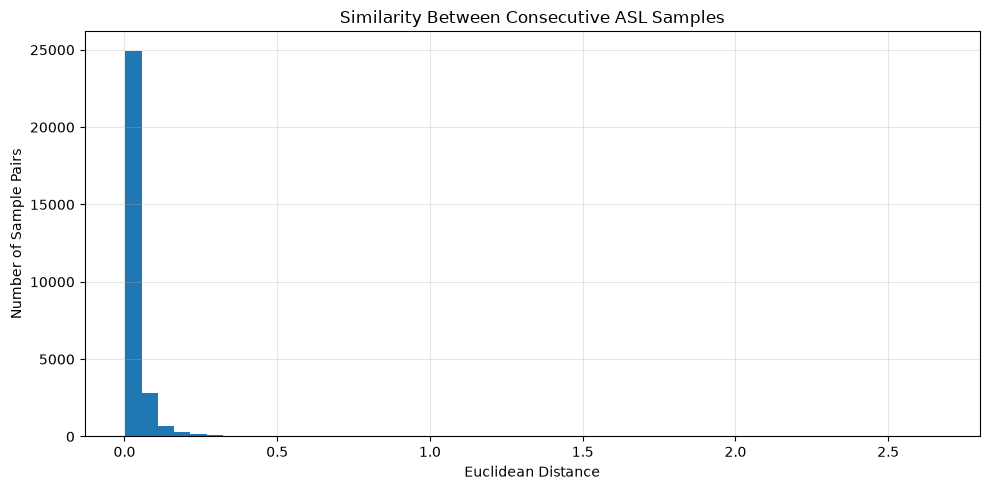

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    close_time_pairs["euclidean_distance"],
    bins=50
)

plt.title("Similarity Between Consecutive ASL Samples")
plt.xlabel("Euclidean Distance")
plt.ylabel("Number of Sample Pairs")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [64]:
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

all_indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(train_indices))
print("Testing samples:", len(test_indices))

Training samples: 51500
Testing samples: 12876


In [66]:
split_lookup = np.full(len(y), "unknown", dtype=object)

split_lookup[train_indices] = "train"
split_lookup[test_indices] = "test"

consecutive_distances_df["first_split"] = (
    consecutive_distances_df["first_sample_index"]
    .map(lambda i: split_lookup[int(i)])
)

consecutive_distances_df["second_split"] = (
    consecutive_distances_df["second_sample_index"]
    .map(lambda i: split_lookup[int(i)])
)

display(consecutive_distances_df.head())

,label,first_sample_index,second_sample_index,time_gap_seconds,euclidean_distance,first_split,second_split
0,A,341,342,0.343,0.041646,train,train
1,A,342,343,0.326,0.042511,train,train
2,A,343,344,0.339,0.033139,train,train
3,A,344,345,0.331,0.066899,train,train
4,A,345,346,0.334,0.026457,train,train


In [67]:
close_pairs = consecutive_distances_df[
    (consecutive_distances_df["time_gap_seconds"] > 0) &
    (consecutive_distances_df["time_gap_seconds"] <= 1)
].copy()

cross_split_pairs = close_pairs[
    close_pairs["first_split"] != close_pairs["second_split"]
].copy()

same_split_pairs = close_pairs[
    close_pairs["first_split"] == close_pairs["second_split"]
].copy()

print("Total close-time pairs:", len(close_pairs))
print("Pairs crossing train/test:", len(cross_split_pairs))
print("Pairs within the same split:", len(same_split_pairs))

print(
    "Cross-split percentage:",
    round(len(cross_split_pairs) / len(close_pairs) * 100, 2),
    "%"
)

display(cross_split_pairs.head(10))

Total close-time pairs: 29224
Pairs crossing train/test: 9388
Pairs within the same split: 19836
Cross-split percentage: 32.12 %


,label,first_sample_index,second_sample_index,time_gap_seconds,euclidean_distance,first_split,second_split
14,A,355,356,0.329,0.014237,train,test
15,A,356,357,0.343,0.027047,test,train
27,A,368,369,0.333,0.034631,train,test
28,A,369,370,0.332,0.183747,test,train
36,A,377,378,0.327,0.021611,train,test
38,A,379,380,0.334,0.048483,test,train
49,A,390,391,0.327,0.008858,train,test
51,A,392,393,0.336,0.025698,test,train
53,A,394,395,0.334,0.015335,train,test
56,A,397,398,0.348,0.014902,test,train


In [68]:
print("Cross-split distance statistics:")
display(cross_split_pairs["euclidean_distance"].describe())

print("\nSame-split distance statistics:")
display(same_split_pairs["euclidean_distance"].describe())

Cross-split distance statistics:


count    9388.000000
mean        0.042044
std         0.104164
min         0.002879
25%         0.014561
50%         0.022332
75%         0.038228
max         2.499144
Name: euclidean_distance, dtype: float64


Same-split distance statistics:


count    19836.000000
mean         0.041368
std          0.107303
min          0.002748
25%          0.014606
50%          0.022479
75%          0.038609
max          2.667351
Name: euclidean_distance, dtype: float64